# Chapter 85: Search, Matching, Unemployment, and Wage Dynamics

This notebook reruns four worked examples from the chapter: when sorting raises output, how a matching function sets finding rates and steady unemployment, moves along and shifts of the Beveridge curve, and monopsony with wage floors. Every number is one of the chapter's hypothetical values; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def pct(fraction, digits=1):
    """Percent from a fraction: pct(0.022) -> '2.2%'."""
    return f"{num(100 * float(fraction), digits)}%"


def assignment_output(F, skills, qualities):
    """assortative-matching (chapter 85): sorted F(sH,qH)+F(sL,qL) against crossed F(sH,qL)+F(sL,qH).

    Book (sH 4, sL 1, qH 3, qL 2): sq gives 14 and 11; s+q gives 10 and 10; s+q-0.4sq gives 4.4 and 5.6.
    """
    (sH, sL), (qH, qL) = skills, qualities
    srt = F(sH, qH) + F(sL, qL)
    crs = F(sH, qL) + F(sL, qH)
    return {"sorted": srt, "crossed": crs, "gain": srt - crs}


def matching(A, U, V, alpha=0.5):
    """search-and-matching-unemployment (chapter 85): M = A U^alpha V^(1-alpha), f = M/U, q = M/V, theta = V/U.

    Book: 0.6 sqrt(800 x 450) = 360, f 0.45, q 0.80, theta 0.5625; A 0.4 gives 240; V 800 gives 480.
    """
    M = A * U ** alpha * V ** (1 - alpha)
    return {"M": M, "f": M / U, "q": M / V, "theta": V / U}


def steady_unemployment(s, f):
    """u* = s / (s + f). search-and-matching-unemployment (chapter 85): 0.03 / 0.48 = 0.0625."""
    return s / (s + f)


def beveridge_required_vacancies(L, U, s, A):
    """beveridge-curve (chapter 85): V with A sqrt(U V) = s (L - U), so V = (s(L-U)/A)^2 / U.

    Book: L 5,000, s 0.04, A 0.8: U 500 gives separations 180 and V 101.25; U 400 gives 184 and
    132.25; A 0.4 at U 400 gives 529.
    """
    sep = s * (L - U)
    return {"separations": sep, "V": (sep / A) ** 2 / U}


def monopsony(a, b, MRP, floor=None):
    """monopsony-labor-market-power (chapter 85): supply w = a + bL, ME = a + 2bL, constant MRP.

    Without a floor: L = (MRP - a) / (2b), w = a + bL. With a floor f (a <= f <= MRP) the firm
    hires everyone willing at f: L = (f - a) / b, never above the competitive (MRP - a) / b;
    a floor above MRP gives L = 0. Book: a 8, b 0.5, MRP 20: L 12, w 14, markdown 6, competitive
    L 24; floor 16 gives L 16; b 0.25 gives L 24, w 14.
    """
    comp = (MRP - a) / b
    if floor is None:
        L = (MRP - a) / (2 * b)
        w = a + b * L
    elif floor > MRP:
        L, w = 0.0, floor
    else:
        w = max(floor, a + b * (MRP - a) / (2 * b))
        L = min((w - a) / b, comp)
    return {"L": L, "w": w, "markdown": MRP - w, "L_comp": comp}


plt.rcParams.update(HOUSE_RC)


labor = SimpleNamespace(assignment_output=assignment_output, matching=matching, steady_unemployment=steady_unemployment, beveridge_required_vacancies=beveridge_required_vacancies, monopsony=monopsony)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'assortative-matching': {'sH': 4,
                          'sL': 1,
                          'qH': 3,
                          'qL': 2,
                          'sorted': 14,
                          'crossed': 11,
                          'sorted_add': 10,
                          'crossed_add': 10,
                          'sorted_neg': 4.4,
                          'crossed_neg': 5.6},
 'search-and-matching-unemployment': {'U': 800,
                                      'V': 450,
                                      'A': 0.6,
                                      's': 0.03,
                                      'M': 360,
                                      'f': 0.45,
                                      'q': 0.8,
                                      'theta': 0.5625,
                                      'u_star': 0.0625,
                                      'A_low': 0.4,
                                      'M_low': 240,
                                      'f_low': 0.3,
                                      'q_low': 0.533,
                                      'u_low': 0.0909,
                                      'V_high': 800,
                                      'M_high': 480,
                                      'f_high': 0.6,
                                      'q_high': 0.6,
                                      'u_high': 0.0476},
 'beveridge-curve': {'L': 5000,
                     's': 0.04,
                     'A': 0.8,
                     'U': 500,
                     'V': 101.25,
                     'hires': 180,
                     'U2': 400,
                     'sep2': 184,
                     'V2': 132.25,
                     'A_low': 0.4,
                     'V_low': 529,
                     'hires_low': 92},
 'monopsony-labor-market-power': {'a': 8,
                                  'b': 0.5,
                                  'MRP': 20,
                                  'L': 12,
                                  'w': 14,
                                  'markdown': 6,
                                  'L_comp': 24,
                                  'floor': 16,
                                  'L_floor': 16,
                                  'b_flat': 0.25,
                                  'L_flat': 24,
                                  'w_flat': 14},
 'constructed': {'assortative-matching': {'sH': [2, 3]},
                 'search-and-matching-unemployment': {'A': [0.7], 'V': [600]},
                 'beveridge-curve': {'U': [600]},
                 'monopsony-labor-market-power': {'b': [1.0], 'floor': [18]}}}


TECH = {
    "sq": (lambda s, q: s * q, "F = sq"),
    "add": (lambda s, q: s + q, "F = s + q"),
    "neg": (lambda s, q: s + q - 0.4 * s * q, "F = s + q - 0.4sq"),
}


def _f_text(tech, s, q):
    if tech == "sq":
        return f"{num(s, 0)}({num(q, 0)})"
    if tech == "add":
        return f"({num(s, 0)} + {num(q, 0)})"
    return f"({num(s, 0)} + {num(q, 0)} - 0.4 x {num(s, 0)} x {num(q, 0)})"


def sorting_picture(tech="sq", sh=4):
    b = BV["assortative-matching"]
    F, name = TECH[tech]
    sl, qh, ql = b["sL"], b["qH"], b["qL"]
    r = labor.assignment_output(F, (sh, sl), (qh, ql))
    srt, crs, gain = r["sorted"], r["crossed"], r["gain"]
    fig, (ax1, ax2) = new_figure(ncols=2)
    ax1.plot([0, 1], [1, 1], color=PALETTE["teal"], linewidth=2.4)
    ax1.plot([0, 1], [0, 0], color=PALETTE["teal"], linewidth=2.4)
    ax1.plot([0, 1], [1, 0], color=PALETTE["terracotta"], linewidth=1.6, linestyle="dashed")
    ax1.plot([0, 1], [0, 1], color=PALETTE["terracotta"], linewidth=1.6, linestyle="dashed")
    for y, t in [(1, f"s_H = {num(sh, 0)}"), (0, "s_L = 1")]:
        mark(ax1, 0, y, t, col="ink", dx=-8, dy=0, ha="right", va="center")
    for y, t in [(1, "q_H = 3"), (0, "q_L = 2")]:
        mark(ax1, 1, y, t, col="ink", dx=8, dy=0, ha="left", va="center")
    label(ax1, 0.5, 1.0, "sorted (solid)", col="teal", dx=0, dy=8, ha="center")
    label(ax1, 0.5, 0.5, "crossed (dashed)", col="terracotta", dx=0, dy=10, ha="center")
    ax1.set_xlim(-0.75, 1.75)
    ax1.set_ylim(-0.4, 1.5)
    ax1.set_xticks([0, 1], ["Technicians", "Plants"])
    ax1.set_yticks([0, 1], ["Low", "High"])
    ax1.set_xlabel("Side of the market")
    ax1.set_ylabel("Rank")
    bar_compare(ax2, ["Sorted", "Crossed"], [srt, crs], colors=["teal", "terracotta"],
                value_labels=[num(srt, 1), num(crs, 1)], ylabel="Total output", xlabel=name)
    ax2.set_ylim(0, 16)
    if gain > 1e-9:
        verdict = f"sorting adds {num(gain, 1)} units"
    elif gain < -1e-9:
        verdict = f"crossed matching beats sorting by {num(-gain, 1)} units"
    else:
        verdict = "the two assignments tie and pairing adds nothing"
    s_text = f"{_f_text(tech, sh, qh)} + {_f_text(tech, sl, ql)}"
    c_text = f"{_f_text(tech, sh, ql)} + {_f_text(tech, sl, qh)}"
    metrics = {"Sorted output": num(srt, 1), "Crossed output": num(crs, 1), "Sorting gain": num(gain, 1)}
    steps = [f"Sorted: {s_text} = {num(srt, 1)}", f"Crossed: {c_text} = {num(crs, 1)}",
             f"Gain = {num(srt, 1)} - {num(crs, 1)} = {num(gain, 1)}: {verdict}"]
    interp = (f"Hypothetical market from the chapter, technology {name}. Sorted output is {s_text} = {num(srt, 1)} "
              f"and crossed output {c_text} = {num(crs, 1)}, so {verdict}.")
    alt = (f"Left: two technicians and two plants linked by sorted and crossed pairings. Right: sorted output "
           f"{num(srt, 1)} and crossed output {num(crs, 1)} under {name}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def matching_picture(a=0.6, vac=450):
    b = BV["search-and-matching-unemployment"]
    U, s = b["U"], b["s"]
    r = labor.matching(a, U, vac)
    M, f, q, th = r["M"], r["f"], r["q"], r["theta"]
    u = labor.steady_unemployment(s, f)
    fig, (ax1, ax2) = new_figure(ncols=2)
    bar_compare(ax1, ["Job finding f", "Vacancy filling q"], [f, q], colors=["teal", "gold"],
                value_labels=[num(f, 3), num(q, 3)], ylabel="Monthly rate", xlabel="Side of the market")
    ax1.set_ylim(0, 1.25)
    bar_compare(ax2, ["Steady u*"], [100 * u], colors=["navy"], value_labels=[pct(u, 2)],
                ylabel="Unemployment share (%)", xlabel="Implied steady state")
    ax2.set_ylim(0, 14)
    hline(ax2, 6.25, "book case 6.25%", col="grey")
    metrics = {"Matches M": num(M, 1), "Job-finding rate f": num(f, 3), "Vacancy-filling rate q": num(q, 3),
               "Tightness theta": num(th, 4), "Steady unemployment u*": pct(u, 2)}
    steps = [f"M = {num(a, 1)} sqrt(800 x {num(vac, 0)}) = {num(a, 1)} x {num(np.sqrt(U * vac), 2)} = {num(M, 1)}",
             f"f = {num(M, 1)} / 800 = {num(f, 3)}; q = {num(M, 1)} / {num(vac, 0)} = {num(q, 3)}",
             f"theta = {num(vac, 0)} / 800 = {num(th, 4)}",
             f"u* = 0.03 / (0.03 + {num(f, 3)}) = {num(u, 4)}, or {pct(u, 2)}"]
    interp = (f"Hypothetical labor force of 10,000 with 800 unemployed. Efficiency {num(a, 1)} and {num(vac, 0)} "
              f"vacancies give {num(M, 1)} matches, so f = {num(M, 1)} / 800 = {num(f, 3)} and q = {num(q, 3)}. "
              f"With separations at 0.03, steady unemployment is 0.03 / (0.03 + {num(f, 3)}) = {pct(u, 2)}.")
    alt = (f"Left: job-finding rate {num(f, 3)} and vacancy-filling rate {num(q, 3)}. Right: steady unemployment "
           f"{pct(u, 2)} against the book case of 6.25 percent.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def beveridge_picture(unemp=500, a=0.8):
    b = BV["beveridge-curve"]
    L, s = b["L"], b["s"]
    r = labor.beveridge_required_vacancies(L, unemp, s, a)
    sep, V = r["separations"], r["V"]
    us = np.linspace(300, 700, 200)
    fig, ax = new_figure()
    for aa, col in [(0.8, "teal"), (0.4, "terracotta")]:
        vs = [labor.beveridge_required_vacancies(L, x, s, aa)["V"] for x in us]
        ax.plot(us, vs, color=PALETTE[col], linewidth=2.2 if aa == a else 1.4,
                linestyle="solid" if aa == a else "dashed")
        lab_u = 330
        label(ax, lab_u, labor.beveridge_required_vacancies(L, lab_u, s, aa)["V"], f"A = {num(aa, 1)}", col=col,
              dx=0, dy=8, ha="center")
    right = unemp >= 550
    mark(ax, unemp, V, f"U = {num(unemp, 0)}, V = {num(V, 2)}", col="navy", dx=-8 if right else 8, dy=-10 if right else 8,
         ha="right" if right else "left", va="top" if right else "bottom")
    ax.set_xlim(300, 720)
    ax.set_ylim(0, 820)
    ax.set_xlabel("Unemployed U")
    ax.set_ylabel("Vacancies V needed for steady flows")
    hires_book = a * np.sqrt(unemp * 101.25)
    metrics = {"Separations s(L - U)": num(sep, 0), "Required vacancies V": num(V, 2),
               "Hires at V = 101.25": num(hires_book, 1)}
    steps = [f"Separations = 0.04 x (5,000 - {num(unemp, 0)}) = {num(sep, 0)}",
             f"V = ({num(sep, 0)} / {num(a, 1)})^2 / {num(unemp, 0)} = {num(sep / a, 1)}^2 / {num(unemp, 0)} = {num(V, 2)}",
             f"Check: {num(a, 1)} sqrt({num(unemp, 0)} x {num(V, 2)}) = {num(a * np.sqrt(unemp * V), 1)} hires"]
    interp = (f"Hypothetical labor force of 5,000 with separation rate 0.04. At U = {num(unemp, 0)}, separations are "
              f"0.04 x {num(L - unemp, 0)} = {num(sep, 0)}, so steady flows need V = ({num(sep, 0)} / {num(a, 1)})^2 / "
              f"{num(unemp, 0)} = {num(V, 2)} vacancies. Changing U moves along a curve; changing A shifts it.")
    alt = (f"Two downward-sloping curves of required vacancies against unemployment, for A = 0.8 and A = 0.4, with a "
           f"point at U = {num(unemp, 0)} and V = {num(V, 2)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def monopsony_picture(slope=0.5, floor=0):
    b = BV["monopsony-labor-market-power"]
    a0, mrp = b["a"], b["MRP"]
    fl = floor if floor else None
    r = labor.monopsony(a0, slope, mrp, fl)
    L, w, comp = r["L"], r["w"], r["L_comp"]
    xs = np.linspace(0, 50, 200)
    fig, ax = new_figure()
    ax.plot(xs, a0 + slope * xs, color=PALETTE["teal"], linewidth=2.2)
    ax.plot(xs, a0 + 2 * slope * xs, color=PALETTE["gold"], linewidth=2.0)
    hline(ax, mrp, "MRP = 20", col="navy", style="solid", x_frac=0.80)
    lx = 12 if slope < 0.4 else min(18 / slope, 46)
    left = lx + 14 < 50
    label(ax, lx, a0 + slope * lx, "supply w = 8 + bL", col="teal", dx=6 if left else -6, dy=-6, va="top",
          ha="left" if left else "right")
    lx2 = min(20 / (2 * slope), 46)
    label(ax, lx2, a0 + 2 * slope * lx2, "ME", col="gold", dx=-6, dy=4, ha="right")
    if fl:
        ax.plot([0, L], [fl, fl], color=PALETTE["terracotta"], linewidth=1.6, linestyle="dashed")
    far = L > 30
    mark(ax, L, w, f"L = {num(L, 0)}, w = {num(w, 0)}", col="terracotta", dx=-8 if far else 8, dy=-10, va="top",
         ha="right" if far else "left")
    ax.set_xlim(0, 50)
    ax.set_ylim(0, 30)
    ax.set_xlabel("Workers L")
    ax.set_ylabel("Wage or cost per worker")
    if fl:
        rule = (f"With a floor of {num(fl, 0)}, (​{num(fl, 0)} - 8) / {num(slope, 2)} = {num(L, 0)} workers "
                f"accept, and each adds 20 > {num(fl, 0)}, so all are hired")
        rule = rule.replace("​", "")
        steps = [f"At w = {num(fl, 0)}: L = ({num(fl, 0)} - 8) / {num(slope, 2)} = {num(L, 0)}",
                 f"MRP 20 is above {num(fl, 0)}, so the firm hires all {num(L, 0)}",
                 f"Markdown = 20 - {num(w, 0)} = {num(20 - w, 0)}; competitive L = 12 / {num(slope, 2)} = {num(comp, 0)}"]
    else:
        rule = (f"Setting ME = 8 + {num(2 * slope, 1)}L equal to 20 gives L = 12 / {num(2 * slope, 1)} = {num(L, 0)} "
                f"and w = 8 + {num(slope, 2)} x {num(L, 0)} = {num(w, 0)}")
        steps = [f"ME = 8 + {num(2 * slope, 1)}L = 20, so L = 12 / {num(2 * slope, 1)} = {num(L, 0)}",
                 f"w = 8 + {num(slope, 2)} x {num(L, 0)} = {num(w, 0)}",
                 f"Markdown = 20 - {num(w, 0)} = {num(20 - w, 0)}; competitive L = 12 / {num(slope, 2)} = {num(comp, 0)}"]
    metrics = {"Employment L": num(L, 0), "Wage w": num(w, 0), "Markdown MRP - w": num(20 - w, 0),
               "Competitive employment": num(comp, 0)}
    interp = (f"Hypothetical workshop from the chapter with supply w = 8 + {num(slope, 2)}L and MRP 20. {rule}. "
              f"The competitive benchmark is L = {num(comp, 0)}.")
    alt = (f"Supply, marginal expenditure and MRP lines; the firm hires {num(L, 0)} workers at a wage of {num(w, 0)}"
           f"{' under a floor of ' + num(fl, 0) if fl else ''}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Assortative matching: sorting pays only with complementarity

Hypothetical skills s_H = 4, s_L = 1 and plant qualities 3 and 2.

$$F(s_H,q_H)+F(s_L,q_L)>F(s_H,q_L)+F(s_L,q_H), \qquad 4(3)+1(2)=14, \qquad 4(2)+1(3)=11$$

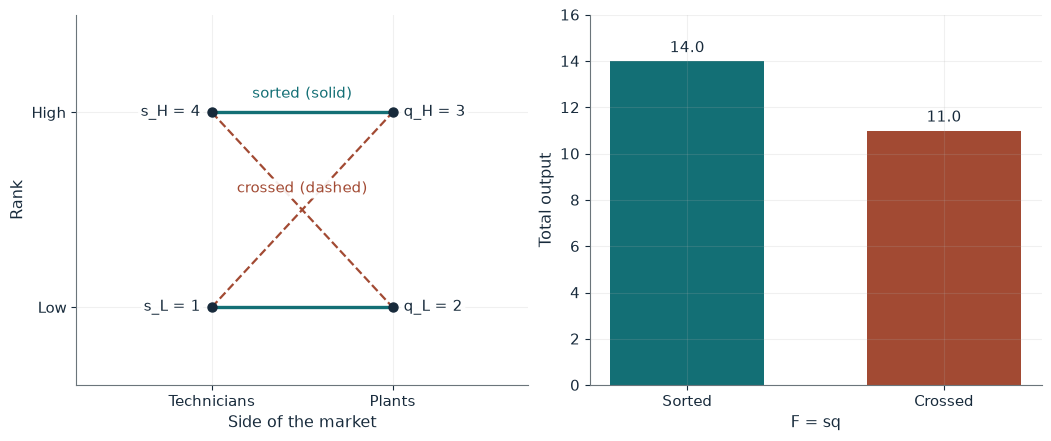

Sorted output   14.0
Crossed output  11.0
Sorting gain    3.0

Worked steps:
  1. Sorted: 4(3) + 1(2) = 14.0
  2. Crossed: 4(2) + 1(3) = 11.0
  3. Gain = 14.0 - 11.0 = 3.0: sorting adds 3.0 units

Hypothetical market from the chapter, technology F = sq. Sorted output is 4(3) + 1(2) = 14.0 and crossed output 4(2) + 1(3) = 11.0, so sorting adds 3.0 units.


In [2]:
show(sorting_picture(tech='sq', sh=4))

Change one input, `tech`, and hold the others at the book's values:

In [3]:
sweep(sorting_picture, 'tech', ['sq', 'add', 'neg'], {'sh': 4}, ['Sorted output', 'Crossed output', 'Sorting gain'])

tech | Sorted output | Crossed output | Sorting gain
sq | 14.0 | 11.0 | 3.0
add | 10.0 | 10.0 | 0.0
neg | 4.4 | 5.6 | -1.2


Complementary output (sq) gains 3 from sorting; additive output ties at 10; a negative interaction makes crossing better by 1.2.

## 2. Search and matching: finding rates and steady unemployment

Hypothetical labor force of 10,000 with 800 unemployed and s = 0.03.

$$M(u,v)=A u^\alpha v^{1-\alpha}, \qquad 0.6\sqrt{800(450)}=360, \qquad u^*=\frac{s}{s+f(\theta)}$$

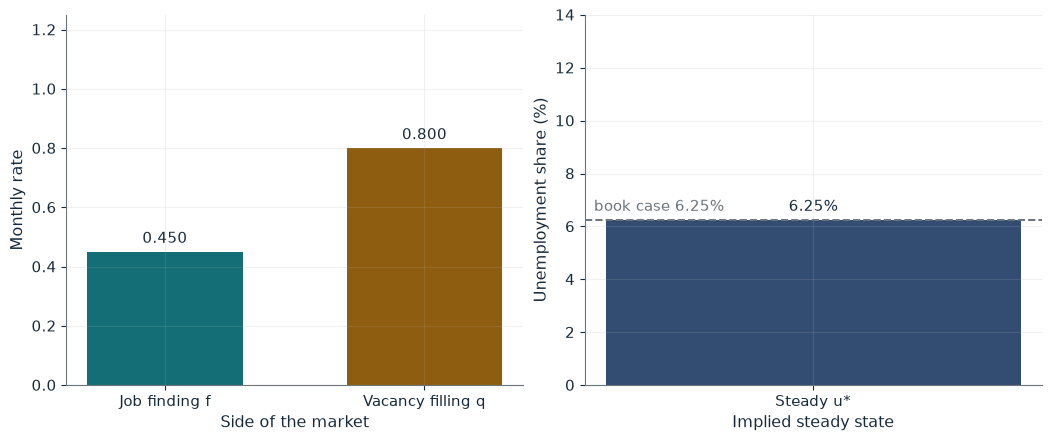

Matches M               360.0
Job-finding rate f      0.450
Vacancy-filling rate q  0.800
Tightness theta         0.5625
Steady unemployment u*  6.25%

Worked steps:
  1. M = 0.6 sqrt(800 x 450) = 0.6 x 600.00 = 360.0
  2. f = 360.0 / 800 = 0.450; q = 360.0 / 450 = 0.800
  3. theta = 450 / 800 = 0.5625
  4. u* = 0.03 / (0.03 + 0.450) = 0.0625, or 6.25%

Hypothetical labor force of 10,000 with 800 unemployed. Efficiency 0.6 and 450 vacancies give 360.0 matches, so f = 360.0 / 800 = 0.450 and q = 0.800. With separations at 0.03, steady unemployment is 0.03 / (0.03 + 0.450) = 6.25%.


In [4]:
show(matching_picture(a=0.6, vac=450))

Change one input, `vac`, and hold the others at the book's values:

In [5]:
sweep(matching_picture, 'vac', [450, 600, 800], {'a': 0.6}, ['Job-finding rate f', 'Vacancy-filling rate q', 'Steady unemployment u*'])

vac | Job-finding rate f | Vacancy-filling rate q | Steady unemployment u*
450 | 0.450 | 0.800 | 6.25%
600 | 0.520 | 0.693 | 5.46%
800 | 0.600 | 0.600 | 4.76%


At the book stocks f = 0.45, q = 0.80 and u* = 6.25 percent. More vacancies raise f but lower q: congestion on the firm side.

## 3. Beveridge curve: moving along versus shifting

Hypothetical L = 5,000, s = 0.04, M = A sqrt(UV).

$$\Delta U=s(L-U)-M, \qquad V=\frac{(184/0.8)^2}{400}=132.25$$

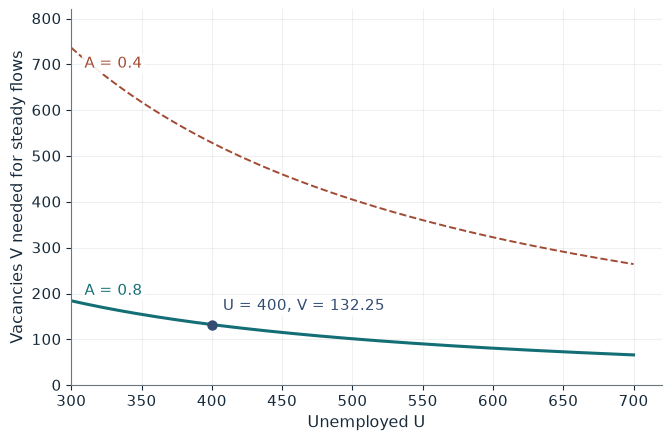

Separations s(L - U)  184
Required vacancies V  132.25
Hires at V = 101.25   161.0

Worked steps:
  1. Separations = 0.04 x (5,000 - 400) = 184
  2. V = (184 / 0.8)^2 / 400 = 230.0^2 / 400 = 132.25
  3. Check: 0.8 sqrt(400 x 132.25) = 184.0 hires

Hypothetical labor force of 5,000 with separation rate 0.04. At U = 400, separations are 0.04 x 4,600 = 184, so steady flows need V = (184 / 0.8)^2 / 400 = 132.25 vacancies. Changing U moves along a curve; changing A shifts it.


In [6]:
show(beveridge_picture(unemp=400, a=0.8))

Change one input, `unemp`, and hold the others at the book's values:

In [7]:
sweep(beveridge_picture, 'unemp', [400, 500, 600], {'a': 0.8}, ['Separations s(L - U)', 'Required vacancies V'])

unemp | Separations s(L - U) | Required vacancies V
400 | 184 | 132.25
500 | 180 | 101.25
600 | 176 | 80.67


Lower unemployment needs more vacancies (along the curve). Halving A at U = 400 raises the requirement from 132.25 to 529, four times as many: the curve shifts out.

## 4. Monopsony: wage floors and mobility

Hypothetical workshop with supply w = 8 + 0.5L and MRP 20.

$$ME(L)=w(L)+Lw'(L), \qquad MRP_L=ME(L)$$

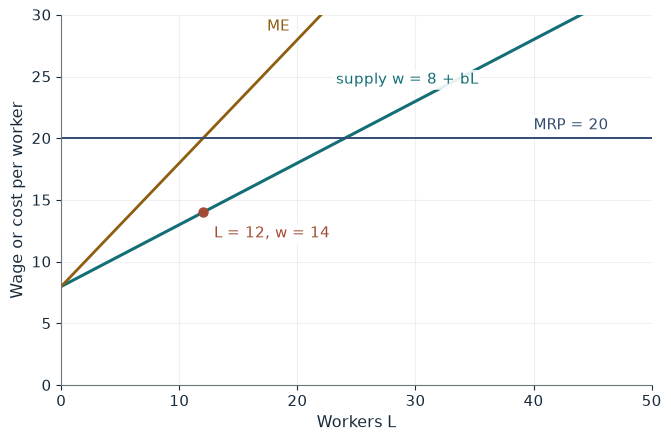

Employment L            12
Wage w                  14
Markdown MRP - w        6
Competitive employment  24

Worked steps:
  1. ME = 8 + 1.0L = 20, so L = 12 / 1.0 = 12
  2. w = 8 + 0.50 x 12 = 14
  3. Markdown = 20 - 14 = 6; competitive L = 12 / 0.50 = 24

Hypothetical workshop from the chapter with supply w = 8 + 0.50L and MRP 20. Setting ME = 8 + 1.0L equal to 20 gives L = 12 / 1.0 = 12 and w = 8 + 0.50 x 12 = 14. The competitive benchmark is L = 24.


In [8]:
show(monopsony_picture(slope=0.5, floor=0))

Change one input, `floor`, and hold the others at the book's values:

In [9]:
sweep(monopsony_picture, 'floor', [0, 16, 18], {'slope': 0.5}, ['Employment L', 'Wage w'])

floor | Employment L | Wage w
0 | 12 | 14
16 | 16 | 16
18 | 20 | 18


The monopsonist hires 12 at 14, a markdown of 6. A floor of 16 raises employment to 16; a floor of 18 raises it to 20. A floor of 0 here means no floor.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

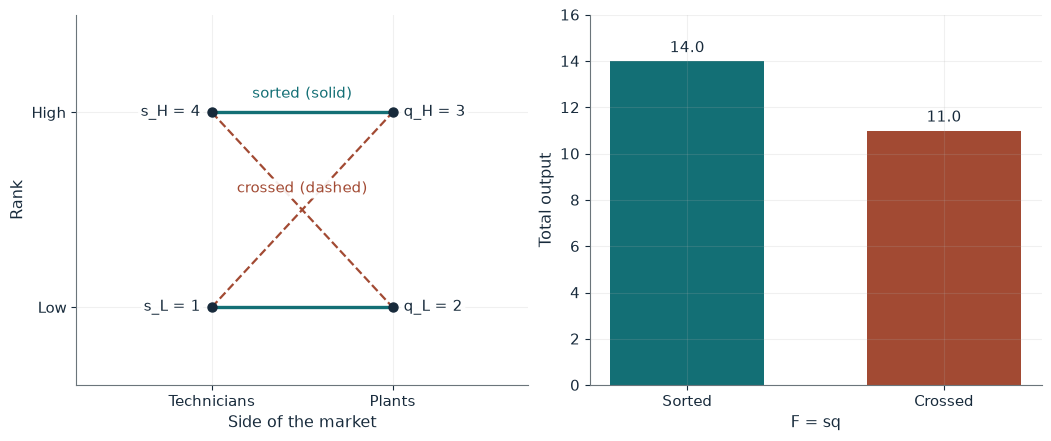

Sorted output   14.0
Crossed output  11.0
Sorting gain    3.0

Worked steps:
  1. Sorted: 4(3) + 1(2) = 14.0
  2. Crossed: 4(2) + 1(3) = 11.0
  3. Gain = 14.0 - 11.0 = 3.0: sorting adds 3.0 units

Hypothetical market from the chapter, technology F = sq. Sorted output is 4(3) + 1(2) = 14.0 and crossed output 4(2) + 1(3) = 11.0, so sorting adds 3.0 units.


In [10]:
show(sorting_picture(tech='sq', sh=4))

## Practice

**1.** With F = sq and s_H = 2, what is the sorting gain?

<details><summary>Answer</summary>

Sorted 2(3) + 1(2) = 8, crossed 2(2) + 1(3) = 7, gain 1.

</details>

**2.** With A = 0.6 and V = 600, what is u*?

<details><summary>Answer</summary>

M = 0.6 sqrt(480,000) = 415.7, f = 0.520, u* = 0.03 / 0.550 = 5.46 percent.

</details>

**3.** At U = 600 and A = 0.8, what V sustains steady flows?

<details><summary>Answer</summary>

Separations 176; V = (176 / 0.8)^2 / 600 = 80.67.

</details>